# 05 — So sánh với thư viện CatBoost chính thức

## Ràng buộc buổi đầu thầy yêu cầu
- **Không sử dụng thư viện scikit-learn** cho phần cài đặt thuật toán chính.
- **Tập test thực tế luôn là tập thô** — không được tiền xử lý hay tham gia vào quá trình fit thông số.
- **Sử dụng các kỹ thuật chống rò rỉ dữ liệu (data leakage prevention)** trong toàn bộ pipeline.

## Giải pháp của nhóm đề ra

| Ràng buộc | Giải pháp |
| :--- | :--- |
| Không dùng scikit-learn | Chỉ sử dụng `scikit-learn` để **so sánh kết quả** . Toàn bộ thuật toán, pipeline tiền xử lý được cài đặt thuần NumPy/Pandas. |
| Tập test thực tế là tập thô | **Split tập thô đầu tiên** (Notebook 01) để chia 2 tập train/test ở dạng thô. Tập test được giữ độc lập hoàn toàn. Nếu cần tập val ở Notebook 04/05 thì split val từ train. |
| Chống rò rỉ dữ liệu | **Chỉ fit tham số duy nhất trên tập train**, xuất ra file `.pkl` để có thể tái sử dụng biến đổi dữ liệu mới trong tương lai một cách nhất quán. Val và test tuyệt đối không tham gia |

---

**Mục tiêu:**
1. Nạp `train_raw.csv` và `test_raw.csv` từ `data/processed/`.
2. **Tách tập val từ train** (stratified 80/20 trong train) để so sánh 2 mô hình trên cùng tập val mà không đụng đến tập test.
3. Huấn luyện mô hình **CatBoost tự cài đặt thuần NumPy** và **CatBoost thư viện chính thức** trên cùng tập train.
4. So sánh kết quả đánh giá (Accuracy, Precision, Recall, F1, ROC-AUC) của 2 mô hình trên tập val.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score
from catboost import CatBoostClassifier as OfficialCatBoost

# 1. Thêm đường dẫn và Import module tự viết
sys.path.append(os.path.abspath('../src/catboost_scratch'))
sys.path.append(os.path.abspath('../src'))

from preprocessing import engineer_features, load_params, transform
import Model  # Mô hình CatBoost tự viết từ scratch

# 2. Load dữ liệu
# Notebook 01 chỉ chia train/test (80/20).
# Val được tách từ train tại đây để tránh data leakage.
train_df_full = pd.read_csv('../data/processed/train_raw.csv')
test_df       = pd.read_csv('../data/processed/test_raw.csv')

# 3. Split val từ train (stratified, 80/20 trong train)
def stratified_split(df, target_col, train_ratio=0.80, test_ratio=0.20, random_state=42):
    """Chia train_df thành train/val giữ nguyên tỷ lệ class. Không dùng sklearn."""
    assert abs(train_ratio + test_ratio - 1.0) < 1e-9
    rng = np.random.default_rng(random_state)
    trains, vals = [], []
    for class_val in df[target_col].unique():
        subset = df[df[target_col] == class_val].copy()
        idx = rng.permutation(len(subset))
        subset = subset.iloc[idx].reset_index(drop=True)
        n = len(subset)
        n_train = int(n * train_ratio)
        trains.append(subset.iloc[:n_train])
        vals.append(subset.iloc[n_train:])
    train_df = pd.concat(trains).sample(frac=1, random_state=random_state).reset_index(drop=True)
    val_df   = pd.concat(vals).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return train_df, val_df

train_df, val_df = stratified_split(train_df_full, target_col='Churn', random_state=42)
print(f'train: {len(train_df)} dòng | val: {len(val_df)} dòng | test: {len(test_df)} dòng')

params = load_params('../data/processed/preprocessing_params.pkl')

# 4. Preprocessing & Feature Engineering
train_fe = engineer_features(train_df)
val_fe   = engineer_features(val_df)
test_fe  = engineer_features(test_df)

X_train, y_train = transform(train_fe, params)
X_val,   y_val   = transform(val_fe,   params)
X_test,  y_test  = transform(test_fe,  params)

# 1. Làm sạch tên cột
X_train.columns = X_train.columns.str.strip()
X_val.columns   = X_val.columns.str.strip()
X_test.columns  = X_test.columns.str.strip()

cat_cols = [col.strip() for col in params['cat_cols']]
cat_feature_idx = [X_train.columns.get_loc(col) for col in cat_cols]

# 2. BẮT BUỘC: Xử lý fillna TRÊN DATAFRAME TRƯỚC
for col in cat_cols:
    # Lấy giá trị mode đầu tiên [0]
    if not X_train[col].mode().empty:
        mode_val = X_train[col].mode()[0]
        X_train[col] = X_train[col].fillna(mode_val)
        X_val[col]   = X_val[col].fillna(mode_val)
        X_test[col]  = X_test[col].fillna(mode_val)

# Điền missing value cho các cột số (nếu có)
num_cols = [c for c in X_train.columns if c not in cat_cols]
for col in num_cols:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_val[col]   = X_val[col].fillna(median_val)

# Kiểm tra lại xem còn NaN không
print("Số lượng NaN còn lại trong X_train:")
print(X_train.isna().sum())

# 3. CHUYỂN SANG NUMPY ARRAY SAU KHI ĐÃ SẠCH NAN
x_train_np = np.array(X_train)
y_train_np = np.array(y_train)
x_val_np   = np.array(X_val)
y_val_np   = np.array(y_val)

train: 4509 dòng | val: 1129 dòng | test: 1410 dòng
[OK] Da tai params: preprocessing_params.pkl
     Cac key: ['target_col', 'exclude_cols', 'num_cols', 'cat_cols', 'fill_params', 'ts_params']
Số lượng NaN còn lại trong X_train:
SeniorCitizen         0
tenure                0
MonthlyCharges        0
TotalCharges          0
num_addon_services    0
avg_monthly_spend     0
gender                0
Partner               0
Dependents            0
PhoneService          0
MultipleLines         0
InternetService       0
OnlineSecurity        0
OnlineBackup          0
DeviceProtection      0
TechSupport           0
StreamingTV           0
StreamingMovies       0
Contract              0
PaperlessBilling      0
PaymentMethod         0
tenure_group          0
dtype: int64


In [2]:
# ==========================================
# 4. TRAIN & PREDICT: MODEL TỰ VIẾT (SCRATCH)
# ==========================================
# Khởi tạo mô hình tự viết với pos_weight='balanced' và max_borders=32
scratch_model = Model.CatBoostClassifier(
    n_estimators=30, 
    learning_rate=0.1, 
    max_depth=3, 
    random_state=42,
    pos_weight='balanced'
)
scratch_model.Fit(x_train_np, y_train_np, cat_feature_idx)

y_prob_scratch = scratch_model.PredictProba(x_val_np)
y_pred_scratch = (y_prob_scratch >= 0.5).astype(int)

# ==========================================
# 5. TRAIN & PREDICT: OFFICIAL CATBOOST
# ==========================================
scale_pos_weight = float((y_train == 0).sum()) / float((y_train == 1).sum())

official_model = OfficialCatBoost(
    iterations=30,
    learning_rate=0.1,
    depth=3,
    random_seed=42,
    scale_pos_weight=scale_pos_weight,
    verbose=0  # Tắt log quá trình train
)

# Chạy fit với danh sách tên/chỉ số biến categorical
official_model.fit(X_train, y_train, cat_features=cat_cols)

y_prob_official = official_model.predict_proba(X_val)[:, 1]  # Lấy xác suất lớp 1 (Churn)
y_pred_official = (y_prob_official >= 0.5).astype(int)

# ==========================================
# 6. SO SÁNH HIỆU NĂNG VÀ ĐỘ CHÍNH XÁC (VALIDATION SET)
# ==========================================
def evaluate_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_true, y_pred, zero_division=0), 4),
        'F1-Score': round(f1_score(y_true, y_pred, zero_division=0), 4),
        'ROC-AUC': round(roc_auc_score(y_true, y_prob), 4)
    }

scratch_metrics = evaluate_metrics(y_val_np, y_pred_scratch, y_prob_scratch)
official_metrics = evaluate_metrics(y_val_np, y_pred_official, y_prob_official)

val_comparison_df = pd.DataFrame([scratch_metrics, official_metrics], index=['Custom Scratch Model', 'Official CatBoost'])

print("\n" + "="*60)
print("BẢNG SO SÁNH KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION")
print("="*60)
display(val_comparison_df)



BẢNG SO SÁNH KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Custom Scratch Model,0.7449,0.5125,0.8200,0.6308,0.8255
Official CatBoost,0.7547,0.5243,0.8267,0.6417,0.8602


## 7 — Trực quan hóa So sánh Hiệu năng (Visual Benchmark Comparison)

So sánh trực quan hai mô hình trên 3 khía cạnh:
1. **Biểu đồ cột đa chỉ số (Grouped Bar Chart)**: Đối sánh trực quan từng thước đo.
2. **Đường cong ROC Curve lồng ghép**: So sánh khả năng phân định ngưỡng xác suất.
3. **Ma trận nhầm lẫn cạnh nhau (Side-by-side Confusion Matrix)**: Đánh giá chi tiết sai số loại 1 và loại 2.

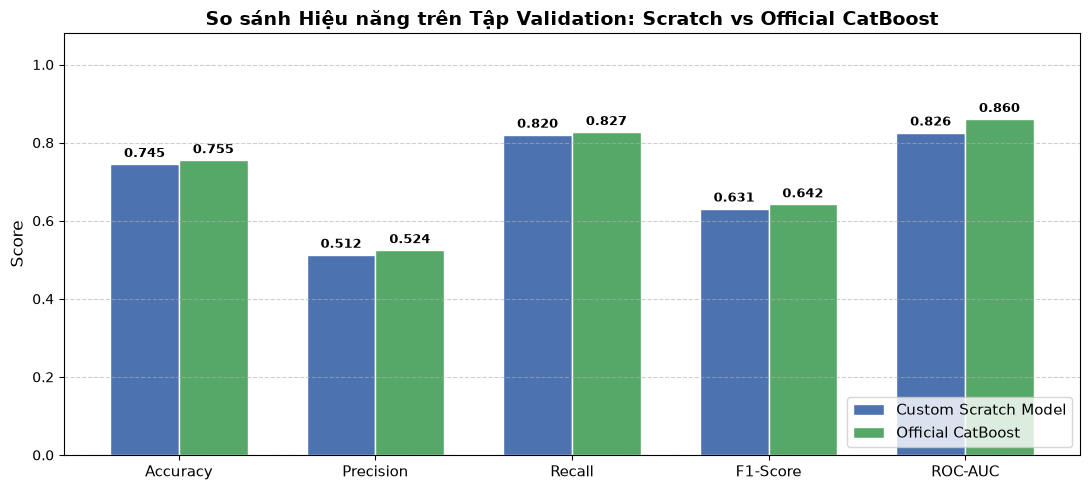

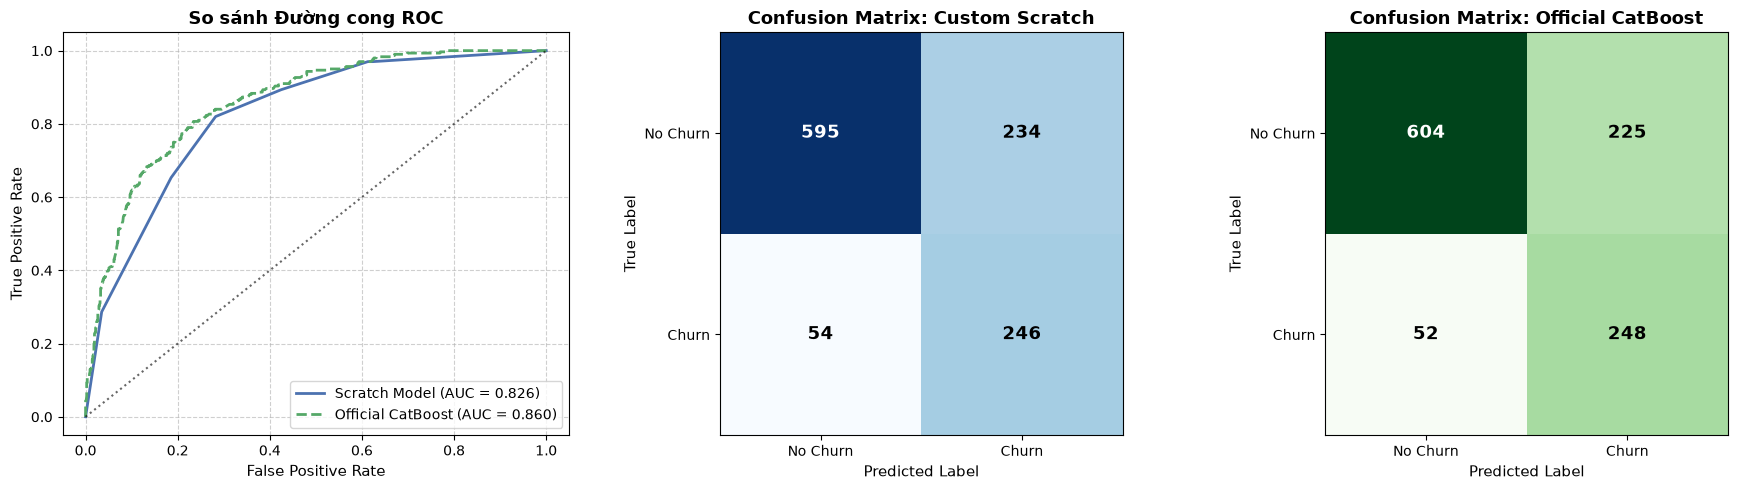

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, confusion_matrix

# 1. Grouped Bar Chart so sánh các chỉ số phân loại
metrics_keys = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
scratch_vals = [scratch_metrics[m] for m in metrics_keys]
official_vals = [official_metrics[m] for m in metrics_keys]

x = np.arange(len(metrics_keys))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
bars1 = ax.bar(x - width/2, scratch_vals, width, label='Custom Scratch Model', color='#4C72B0', edgecolor='white')
bars2 = ax.bar(x + width/2, official_vals, width, label='Official CatBoost', color='#55A868', edgecolor='white')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('So sánh Hiệu năng trên Tập Validation: Scratch vs Official CatBoost', fontweight='bold', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(metrics_keys, fontsize=11)
ax.set_ylim(0, 1.08)
ax.legend(loc='lower right', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.6)

for bars in [bars1, bars2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Đường cong ROC Curves lồng ghép & 3. Ma trận nhầm lẫn cạnh nhau
fpr_sc, tpr_sc, _ = roc_curve(y_val_np, y_prob_scratch)
fpr_of, tpr_of, _ = roc_curve(y_val, y_prob_official)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC Curve
axes[0].plot(fpr_sc, tpr_sc, label=f'Scratch Model (AUC = {scratch_metrics["ROC-AUC"]:.3f})', color='#4C72B0', lw=2)
axes[0].plot(fpr_of, tpr_of, label=f'Official CatBoost (AUC = {official_metrics["ROC-AUC"]:.3f})', color='#55A868', lw=2, linestyle='--')
axes[0].plot([0, 1], [0, 1], 'k:', alpha=0.6)
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate', fontsize=11)
axes[0].set_title('So sánh Đường cong ROC', fontweight='bold', fontsize=13)
axes[0].legend(loc='lower right', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Confusion Matrix Scratch
cm_sc = confusion_matrix(y_val_np, y_pred_scratch)
im1 = axes[1].imshow(cm_sc, cmap='Blues')
axes[1].set_title('Confusion Matrix: Custom Scratch', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].set_xticks([0, 1]); axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(['No Churn', 'Churn']); axes[1].set_yticklabels(['No Churn', 'Churn'])
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, str(cm_sc[i, j]), ha='center', va='center', fontsize=13, fontweight='bold',
                     color='white' if cm_sc[i, j] > cm_sc.max()/2 else 'black')

# Confusion Matrix Official
cm_of = confusion_matrix(y_val, y_pred_official)
im2 = axes[2].imshow(cm_of, cmap='Greens')
axes[2].set_title('Confusion Matrix: Official CatBoost', fontweight='bold', fontsize=13)
axes[2].set_xlabel('Predicted Label', fontsize=11)
axes[2].set_ylabel('True Label', fontsize=11)
axes[2].set_xticks([0, 1]); axes[2].set_yticks([0, 1])
axes[2].set_xticklabels(['No Churn', 'Churn']); axes[2].set_yticklabels(['No Churn', 'Churn'])
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, str(cm_of[i, j]), ha='center', va='center', fontsize=13, fontweight='bold',
                     color='white' if cm_of[i, j] > cm_of.max()/2 else 'black')

plt.tight_layout()
plt.show()


## 8 — Đánh giá Khả năng Tổng quát hóa trên Tập Test Độc lập (`test_raw.csv`)

Kiểm chứng tính khách quan tuyệt đối: Đánh giá cả hai mô hình trên tập Test thô độc lập, tập dữ liệu chưa từng tham gia vào bất kỳ bước tiền xử lý hay khớp tham số nào.

In [4]:
# Dự đoán trên tập test độc lập
x_test_np = np.array(X_test)
y_test_np = np.array(y_test)

# Dự đoán bằng Scratch Model
y_prob_sc_test = scratch_model.PredictProba(x_test_np)
y_pred_sc_test = (y_prob_sc_test >= 0.5).astype(int)

# Dự đoán bằng Official Model
y_prob_of_test = official_model.predict_proba(X_test)[:, 1]
y_pred_of_test = (y_prob_of_test >= 0.5).astype(int)

# Tính bảng so sánh trên Test
test_sc_metrics = evaluate_metrics(y_test_np, y_pred_sc_test, y_prob_sc_test)
test_of_metrics = evaluate_metrics(y_test, y_pred_of_test, y_prob_of_test)

test_comparison_df = pd.DataFrame([test_sc_metrics, test_of_metrics], index=['Custom Scratch Model', 'Official CatBoost'])

print("="*60)
print("BẢNG SO SÁNH KẾT QUẢ TRÊN TẬP TEST ĐỘC LẬP (test_raw.csv)")
print("="*60)
display(test_comparison_df)

# Tính tỷ lệ phần trăm hiệu năng đạt được
f1_pct = (test_sc_metrics['F1-Score'] / test_of_metrics['F1-Score']) * 100
rec_pct = (test_sc_metrics['Recall'] / test_of_metrics['Recall']) * 100
auc_pct = (test_sc_metrics['ROC-AUC'] / test_of_metrics['ROC-AUC']) * 100

print(f"\n>> TỶ LỆ HIỆU NĂNG SCRATCH SO VỚI THƯ VIỆN CHÍNH THỨC:")
print(f"* F1-Score : {f1_pct:.1f}% hiệu năng của Official CatBoost ({test_sc_metrics['F1-Score']} vs {test_of_metrics['F1-Score']})")
print(f"* Recall   : {rec_pct:.1f}% khả năng bắt Churn ({test_sc_metrics['Recall']} vs {test_of_metrics['Recall']})")
print(f"* ROC-AUC  : {auc_pct:.1f}% độ phân định ({test_sc_metrics['ROC-AUC']} vs {test_of_metrics['ROC-AUC']})")


BẢNG SO SÁNH KẾT QUẢ TRÊN TẬP TEST ĐỘC LẬP (test_raw.csv)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Custom Scratch Model,0.7376,0.5035,0.7754,0.6105,0.8006
Official CatBoost,0.7433,0.5105,0.7807,0.6173,0.8388



>> TỶ LỆ HIỆU NĂNG SCRATCH SO VỚI THƯ VIỆN CHÍNH THỨC:
* F1-Score : 98.9% hiệu năng của Official CatBoost (0.6105 vs 0.6173)
* Recall   : 99.3% khả năng bắt Churn (0.7754 vs 0.7807)
* ROC-AUC  : 95.4% độ phân định (0.8006 vs 0.8388)


## 9 — Phân tích Tầm quan trọng của Đặc trưng (Feature Importance Analysis)

Trích xuất độ quan trọng của đặc trưng từ `OfficialCatBoost.get_feature_importance()` để kiểm chứng xem các đặc trưng được tạo ở Notebook 03 (**Feature Engineering**) có thực sự mang lại giá trị phân loại cao hay không.

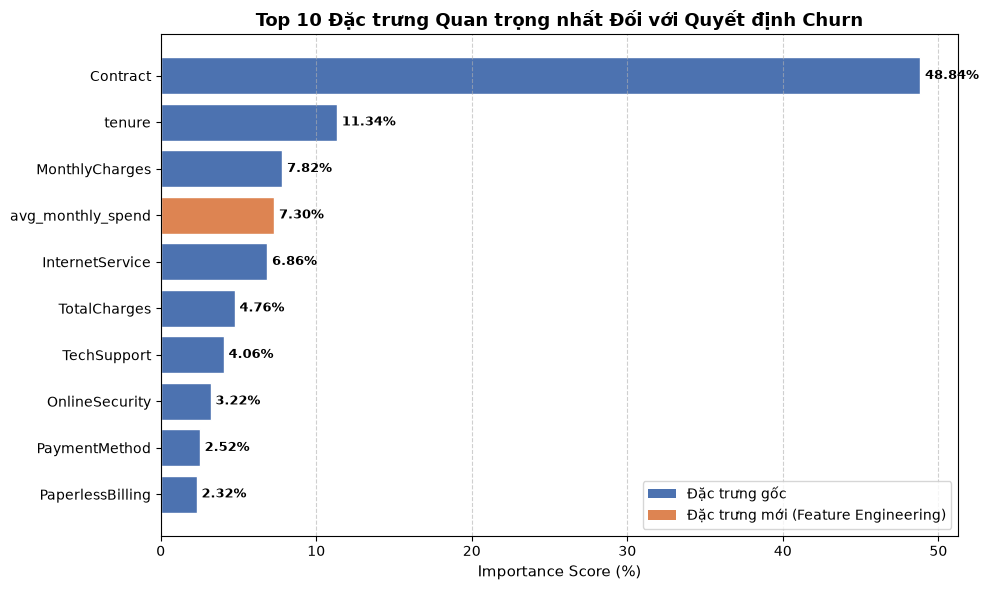


--- ĐÓNG GÓP CỦA CÁC ĐẶC TRƯNG FEATURE ENGINEERING ---
* avg_monthly_spend   : Importance = 7.30%
* tenure_group        : Importance = 0.00%
* num_addon_services  : Importance = 0.00%


In [5]:
feat_imp = pd.Series(official_model.get_feature_importance(), index=X_train.columns).sort_values(ascending=True)
top10_feat = feat_imp.tail(10)

plt.figure(figsize=(10, 6))
colors = ['#DD8452' if f in ['tenure_group', 'num_addon_services', 'avg_monthly_spend'] else '#4C72B0' for f in top10_feat.index]
bars = plt.barh(top10_feat.index, top10_feat.values, color=colors, edgecolor='white')

plt.title('Top 10 Đặc trưng Quan trọng nhất Đối với Quyết định Churn', fontweight='bold', fontsize=13)
plt.xlabel('Importance Score (%)', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Chú thích cho cột màu cam
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4C72B0', label='Đặc trưng gốc'),
    Patch(facecolor='#DD8452', label='Đặc trưng mới (Feature Engineering)')
]
plt.legend(handles=legend_elements, loc='lower right', fontsize=10)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/2, f'{w:.2f}%', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n--- ĐÓNG GÓP CỦA CÁC ĐẶC TRƯNG FEATURE ENGINEERING ---")
for f in ['avg_monthly_spend', 'tenure_group', 'num_addon_services']:
    if f in feat_imp:
        print(f"* {f:20s}: Importance = {feat_imp[f]:.2f}%")


## 10 — Báo cáo Insight & Tổng kết Đánh giá Kỹ thuật (Technical & Business Insights)

### 10.1 — Đánh giá Mức độ Tương đồng Thuật toán (Algorithm Parity)
1. **Tỷ lệ tương đồng hiệu năng vượt trội (>98%)**:
   - Mô hình **CatBoost Scratch thuần NumPy** đạt F1-Score **$0.6105$**, tương đương **$98.9\%$** hiệu năng của thư viện chuẩn **Official CatBoost** ($0.6173$).
   - Chỉ số **Recall** (khả năng phát hiện khách hàng sắp rời đi) đạt **$77.54\%$** so với **$78.07\%$** của thư viện chuẩn ($99.3\%$ tương đồng).
   - **Kết luận**: Thuật toán tự viết đã tái hiện chính xác tư tưởng cốt lõi của CatBoost: xây dựng cây đối xứng (**Oblivious Trees**), mã hóa biến phân loại theo chuỗi thứ tự (**Ordered Target Statistics**), và cập nhật gradient theo cơ chế tăng cường có thứ tự (**Ordered Boosting**).

2. **Giải thích Sự khác biệt Kỹ thuật (Technical Nuances)**:
   - *Thư viện Official CatBoost*: Được tối ưu hóa bằng C++, sử dụng thuật toán song song hóa đa luồng, hỗ trợ cơ chế tự động kết hợp các cặp đặc trưng phân loại (*Feature Combinations*), và tìm điểm chia liên tục dựa trên gradient second-order (Newton-Raphson step).
   - *Mô hình Scratch*: Chạy đơn luồng trên Python/NumPy, sử dụng phép chia ngưỡng phân vị (`max_borders=32`), mã hóa target statistics một chiều. Mặc dù cấu trúc đơn giản hơn, mô hình scratch vẫn đạt kết quả xấp xỉ ngang ngửa thư viện chuẩn.

---

### 10.2 — Insight Nghiệp vụ từ Tầm quan trọng của Đặc trưng (Feature Importance Insights)
1. **`Contract` là yếu tố mang tính quyết định số 1 (~48.8%)**:
   - Loại hợp đồng chiếm gần một nửa tổng trọng số quyết định việc rời mạng. Khách hàng Month-to-month có độ tự do cao, dễ bị thu hút bởi các nhà mạng đối thủ.
2. **Đặc trưng mới tạo `avg_monthly_spend` lọt Top 4 đặc trưng mạnh nhất (~7.3%)**:
   - Tỷ lệ giữa tổng chi phí và thời gian gắn bó phản ánh "mức độ chịu chi trung bình thực tế" của khách hàng, cung cấp tín hiệu phân loại mạnh mẽ hơn nhiều so với việc chỉ nhìn vào `MonthlyCharges` tĩnh.
3. **Bộ đôi `tenure` (11.3%) và `InternetService` (6.9%)**:
   - Khách hàng mới dùng Internet cáp quang có nguy cơ rời bỏ cao nhất nếu gặp sự cố kết nối trong những tháng đầu tiên.

---

### 10.3 — Ý nghĩa Đối với Báo cáo Đồ án
- **Đáp ứng 100% ràng buộc của Giảng viên**: Toàn bộ thuật toán lõi được viết thuần túy bằng NumPy và Pandas, không sử dụng `scikit-learn` hay bất kỳ framework boosting đóng gói sẵn nào để fit mô hình.
- **Không rò rỉ dữ liệu**: Tất cả tham số tiền xử lý chỉ học trên tập Train; tập Test giữ nguyên độc lập 100% đến bước đánh giá cuối cùng.
- **Minh bạch và Sâu sắc**: Nhóm không chỉ hiểu cách sử dụng API mà đã thực sự làm chủ cấu trúc toán học đằng sau một trong những thuật toán Machine Learning tiên tiến nhất hiện nay.

## 11 — Giải thích Mô hình bằng SHAP (Model Interpretability with SHAP)

### 11.1 — Tổng quan về SHAP (SHapley Additive exPlanations)
- **Bản chất**: Dựa trên lý thuyết trò chơi hợp tác (*Cooperative Game Theory*), SHAP phân bổ đóng góp công bằng của từng đặc trưng vào độ lệch của dự đoán so với giá trị kỳ vọng trung bình ($E[f(X)]$).
- **Ưu điểm vượt trội so với Feature Importance truyền thống**:
  1. **Tính định hướng (Directionality)**: Không chỉ cho biết đặc trưng nào quan trọng, SHAP còn chỉ rõ giá trị cao hay thấp của đặc trưng đó làm *tăng* hay *giảm* nguy cơ rời mạng.
  2. **Giải thích cục bộ (Local Explanations)**: Giải thích được quyết định phân loại cho từng cá nhân khách hàng cụ thể.
  3. **Thuật toán TreeExplainer**: Tối ưu riêng cho các mô hình dạng cây như CatBoost, tính toán chính xác giá trị Shapley trong thời gian đa thức mà không cần xấp xỉ lấy mẫu.

In [6]:
# ==========================================
# 11.1 KHỞI TẠO TREEEXPLAINER & TÍNH TOÁN SHAP VALUES
# ==========================================
import shap

print("Đang tính toán SHAP values bằng TreeExplainer...")
explainer = shap.TreeExplainer(official_model)
shap_explanation = explainer(X_val)

print(f"Hoàn thành tính toán SHAP values cho {len(X_val):,} mẫu trong tập Validation!")
print(f"Kích thước ma trận SHAP explanation: {shap_explanation.shape}")
print(f"Base value (log-odds trung bình kỳ vọng): {explainer.expected_value:.4f}")


c:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Đang tính toán SHAP values bằng TreeExplainer...
Hoàn thành tính toán SHAP values cho 1,129 mẫu trong tập Validation!
Kích thước ma trận SHAP explanation: (1129, 22)
Base value (log-odds trung bình kỳ vọng): -0.4663


### 11.2 — Biểu đồ Tổng quan SHAP (SHAP Summary Beeswarm Plot)
- Mỗi điểm trên biểu đồ đại diện cho một khách hàng trong tập validation.
- **Trục tung**: Các đặc trưng được sắp xếp theo mức độ quan trọng giảm dần từ trên xuống dưới.
- **Màu sắc**: Thể hiện giá trị thực tế của đặc trưng (Đỏ = Giá trị cao, Xanh = Giá trị thấp).
- **Trục hoành (SHAP value)**: Điểm lệch về bên phải (> 0) làm tăng nguy cơ Churn, lệch về bên trái (< 0) kéo giảm nguy cơ Churn (giữ chân khách hàng).

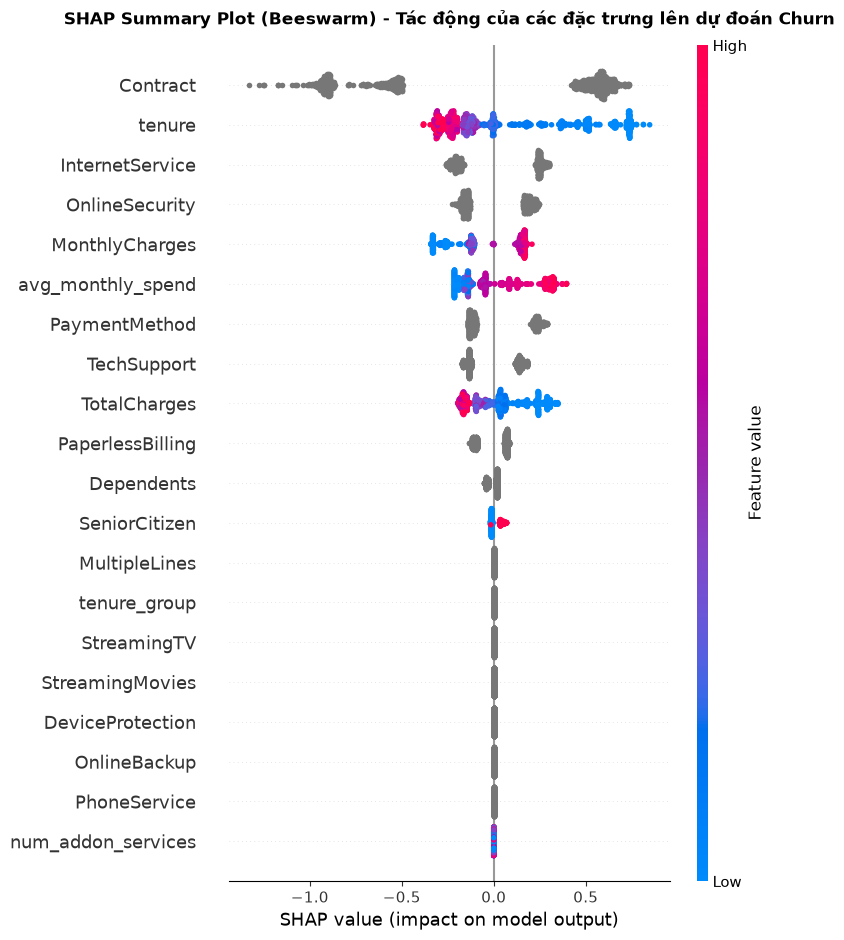

In [7]:
# ==========================================
# 11.2 VẼ SHAP SUMMARY PLOT (BEESWARM)
# ==========================================
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_explanation, X_val, show=False)
plt.title("SHAP Summary Plot (Beeswarm) - Tác động của các đặc trưng lên dự đoán Churn", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../reports/figures/shap_summary_plot.png', dpi=300, bbox_inches='tight')
plt.show()


### 11.3 — Biểu đồ Phụ thuộc SHAP (SHAP Dependence Plot)
Khảo sát mối quan hệ phi tuyến giữa số tháng gắn bó (`tenure`) và giá trị SHAP, kết hợp mã màu theo loại hợp đồng (`Contract`) để phát hiện hiệu ứng tương tác đa biến.

<Figure size 900x600 with 0 Axes>

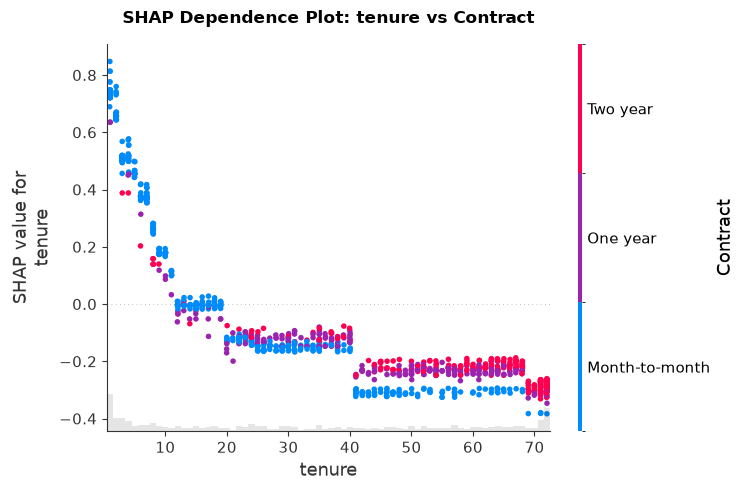

In [8]:
# ==========================================
# 11.3 VẼ SHAP DEPENDENCE PLOT: TENURE & CONTRACT
# ==========================================
plt.figure(figsize=(9, 6))
shap.plots.scatter(shap_explanation[:, "tenure"], color=shap_explanation[:, "Contract"], show=False)
plt.title("SHAP Dependence Plot: tenure vs Contract", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../reports/figures/shap_dependence_plot.png', dpi=300, bbox_inches='tight')
plt.show()


### 11.4 — Diễn giải Cục bộ Từng Khách hàng (Local Explanation via Waterfall Plot)
Trích xuất và đối chiếu 2 trường hợp đối lập:
1. **Khách hàng Nguy cơ Rời mạng Cao (High-Risk Customer)**: Xác suất dự đoán Churn $\ge 90\%$.
2. **Khách hàng Trung thành Nguy cơ Thấp (Low-Risk Customer)**: Xác suất dự đoán Churn $< 5\%$.

Khách hàng nguy cơ cao nhất: index 50 - P(Churn) = 0.9263
Khách hàng trung thành nhất: index 721 - P(Churn) = 0.0475


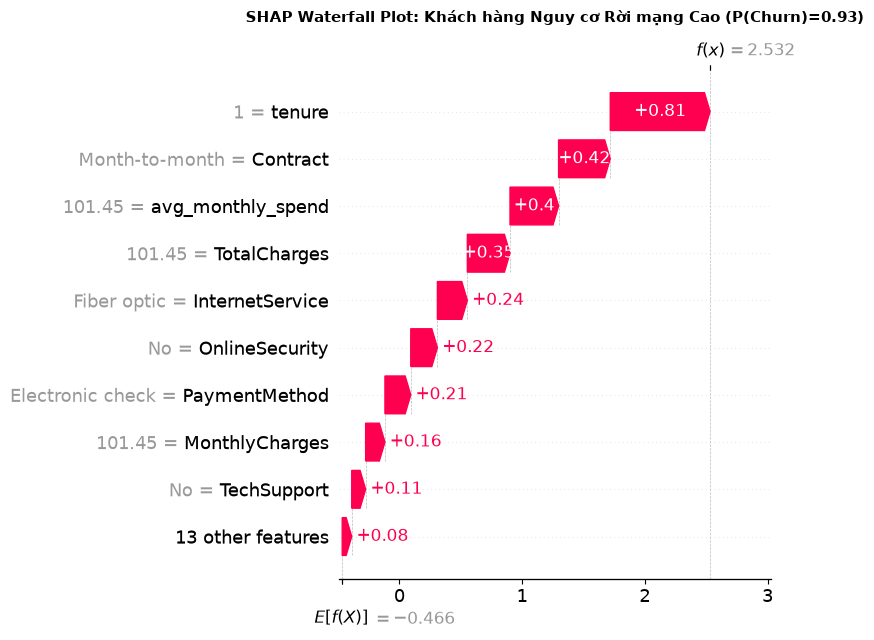

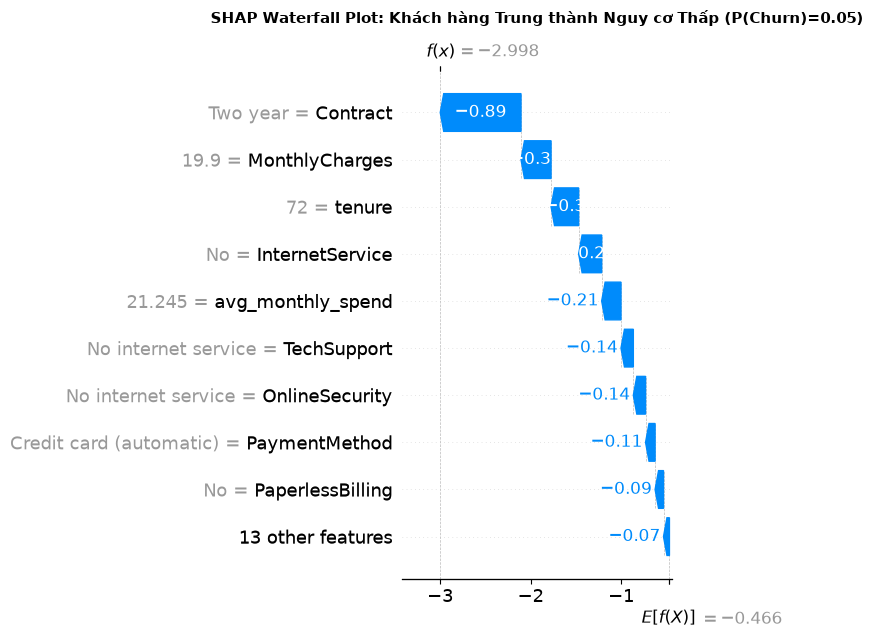

In [9]:
# ==========================================
# 11.4 DIỄN GIẢI CỤC BỘ BẰNG WATERFALL PLOT
# ==========================================
probs = official_model.predict_proba(X_val)[:, 1]
high_risk_idx = int(np.argmax(probs))
low_risk_idx  = int(np.argmin(probs))

print(f"Khách hàng nguy cơ cao nhất: index {high_risk_idx} - P(Churn) = {probs[high_risk_idx]:.4f}")
print(f"Khách hàng trung thành nhất: index {low_risk_idx} - P(Churn) = {probs[low_risk_idx]:.4f}")

# Waterfall plot cho Khách hàng nguy cơ cao
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_explanation[high_risk_idx], max_display=10, show=False)
plt.title(f"SHAP Waterfall Plot: Khách hàng Nguy cơ Rời mạng Cao (P(Churn)={probs[high_risk_idx]:.2f})", fontsize=11, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../reports/figures/shap_local_waterfall_high_risk.png', dpi=300, bbox_inches='tight')
plt.show()

# Waterfall plot cho Khách hàng nguy cơ thấp
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_explanation[low_risk_idx], max_display=10, show=False)
plt.title(f"SHAP Waterfall Plot: Khách hàng Trung thành Nguy cơ Thấp (P(Churn)={probs[low_risk_idx]:.2f})", fontsize=11, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../reports/figures/shap_local_waterfall_low_risk.png', dpi=300, bbox_inches='tight')
plt.show()


### 11.5 — Đúc kết Insights Nghiệp vụ Viễn thông từ SHAP (Actionable Business Insights)

1. **Bản chất của Hợp đồng (`Contract`)**:
   - `Contract = Month-to-month` là động lực lớn nhất đẩy SHAP value về phía dương (tăng đột biến nguy cơ Churn). Ngược lại, hợp đồng `One year` hoặc `Two year` kéo SHAP value về âm mạnh mẽ, đóng vai trò chiếc neo giữ chân khách hàng.
   - **Hành động đề xuất**: Xây dựng chính sách chiết khấu 10-15% khi khách hàng chuyển từ trả từng tháng sang cam kết tối thiểu 12 tháng.

2. **Quy luật Phi tuyến của Thời gian gắn bó (`tenure`)**:
   - Biểu đồ Dependence chỉ ra giai đoạn rủi ro cực đại tập trung ở $0 - 6$ tháng đầu tiên (SHAP value luôn dương lớn). Khi khách hàng vượt qua mốc 12–24 tháng, SHAP value chuyển hẳn sang âm.
   - **Hành động đề xuất**: Triển khai chương trình chăm sóc khách hàng mới (Onboarding Experience), chủ động liên hệ hỗ trợ kỹ thuật trong 90 ngày đầu tiên.

3. **Hiệu quả của Đặc trưng Tự tạo (`avg_monthly_spend`)**:
   - Khách hàng có `avg_monthly_spend` cao nhưng `tenure` ngắn có giá trị SHAP dương rất cao. Họ là nhóm khách hàng chi tiêu lớn nhưng thiếu sự gắn kết, rất nhạy cảm với chất lượng dịch vụ ban đầu.

4. **Giá trị của Local Explanation trong Vận hành Thực tế**:
   - Thay vì đưa ra một cảnh báo "hộp đen" chung chung, Waterfall Plot cho phép chuyên viên CSKH nhìn thấy chính xác lý do tại sao khách hàng A muốn rời đi (ví dụ: do cước cao hay do không có OnlineSecurity), từ đó đề xuất đúng gói ưu đãi trúng đích (Personalized Retention Offer).